In [65]:
from dotenv import load_dotenv
from pyarrow.lib import Sequence

load_dotenv()

from typing import TypedDict, List, Annotated
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import BaseMessage, SystemMessage, AIMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode

In [66]:
model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")


In [67]:
class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]


In [68]:
@tool
def add(a: int, b: int):
    """this will add two number"""
    return a + b


@tool
def sub(a: int, b: int):
    """this will subtract two number"""
    return a - b


@tool
def mul(a: int, b: int):
    """this will multiply two number"""
    return a * b


@tool
def div(a: int, b: int):
    """this will division two number"""
    return a / b

In [69]:

MODEL_CALL_NODE = 'modelcall'
TOOLS_NODE = 'tools'

tools = [add, sub, mul, div]

model = model.bind_tools(tools)


def model_call(state: AgentState):
    system_prompt = SystemMessage(
        content="You are an Ai assistant,Please answer my query to the best of your ability")
    prompt = [system_prompt] + state['messages']
    response = model.invoke(prompt)
    return {'messages': state['messages'] + [response]}


def should_continue(state: AgentState):
    message = state['messages']
    last_msg = message[-1]
    if not last_msg.tool_calls:
        return 'end'
    else:
        return 'continue'


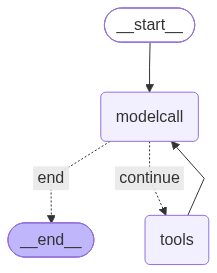

In [70]:

graph = StateGraph(AgentState)
graph.add_node(MODEL_CALL_NODE, model_call)

tools_node = ToolNode(tools=tools)

graph.add_node(TOOLS_NODE, tools_node)

graph.add_edge(START, MODEL_CALL_NODE)
graph.add_conditional_edges(
    MODEL_CALL_NODE, should_continue,
    {
        'end': END,
        'continue': TOOLS_NODE
    }
)
graph.add_edge(TOOLS_NODE, MODEL_CALL_NODE)
graph.add_edge(MODEL_CALL_NODE, END)

bot = graph.compile()
bot

In [71]:
def print_stream(stream):
    for s in stream:
        message = s['messages'][-1]
        if isinstance(message, tuple):
            print(message)
        elif (isinstance(message, AIMessage) and
              isinstance(message.content, List) and
              len(message.content) > 0):
            print(message.text)
        else:
            message.pretty_print()


user_input = {"messages": [("user", "Add 4 and 2 and then calculate product with 6. also tell me a joke at the end")]}

print_stream(bot.stream(user_input, stream_mode="values"))

print("Application Exit.....")

================================ Human Message =================================

Add 4 and 2 and then calculate product with 6. also tell me a joke at the end
================================== Ai Message ==================================

[]
Tool Calls:
  add (call_2543449)
 Call ID: call_2543449
  Args:
    b: 2
    a: 4
================================= Tool Message =================================
Name: add

6
================================== Ai Message ==================================

[]
Tool Calls:
  mul (call_1784150)
 Call ID: call_1784150
  Args:
    a: 6
    b: 6
================================= Tool Message =================================
Name: mul

36
First, adding 4 and 2 gives **6**. 
Then, calculating the product of 6 and 6 gives **36**.

Here is a joke for you:

Why don't skeletons fight each other? 
Because they don't have the guts!
Application Exit.....
